# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [1]:
# Escribe aquí tu código para descargar los datos de tus 3 activos elegidos
import yfinance as yf

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual básica
sns.set_theme(style="whitegrid")

# Para que los gráficos aparezcan dentro del notebook
%matplotlib inline

In [2]:

tickers = ["C","CSCO","OXY"]

precios = yf.download(
    tickers,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=True
)

precios.head()


[*********************100%***********************]  3 of 3 completed


Price           Close                             High                        \
Ticker              C       CSCO        OXY          C       CSCO        OXY   
Date                                                                           
2024-01-02  49.015568  46.821125  57.020267  49.117222  47.145566  57.865363   
2024-01-03  49.570042  47.185448  57.552025  50.244652  47.344260  57.722944   
2024-01-04  49.690178  46.783756  56.137192  50.595820  47.185451  57.969817   
2024-01-05  50.207687  46.793087  55.966270  50.521886  47.054656  56.564486   
2024-01-08  49.911964  47.138733  55.330082  49.985896  47.176101  55.339576   

Price             Low                             Open                        \
Ticker              C       CSCO        OXY          C       CSCO        OXY   
Date                                                                           
2024-01-02  47.305935  46.580115  56.877838  47.407589  46.802589  57.143710   
2024-01-03  48.267026  46.652965  56.441053  49.209634  46.867826  56.621470   
2024-01-04  49.588524  46.699680  56.013753  49.828794  47.120058  57.770413   
2024-01-05  49.801070  46.587566  55.633931  49.930447  46.877163  56.498018   
2024-01-08  48.997083  46.419414  54.428012  49.893485  46.475466  55.045219   

Price         Volume                      
Ticker             C      CSCO       OXY  
Date                                      
2024-01-02  24784900  20242900   7456200  
2024-01-03  30897600  20303900   7269300  
2024-01-04  23714300  18134100   9423300  
2024-01-05  17782200  13989300   8016800  
2024-01-08  17359500  18070300  10343500

## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

In [4]:
# 1. Extraer los precios de cierre
cierre = precios["Close"]

cierre.head()


Ticker,C,CSCO,OXY
Date,,,
2024-01-02,49.015568,46.821125,57.020267
2024-01-03,49.570042,47.185448,57.552025
2024-01-04,49.690178,46.783756,56.137192
2024-01-05,50.207687,46.793087,55.966270
2024-01-08,49.911964,47.138733,55.330082


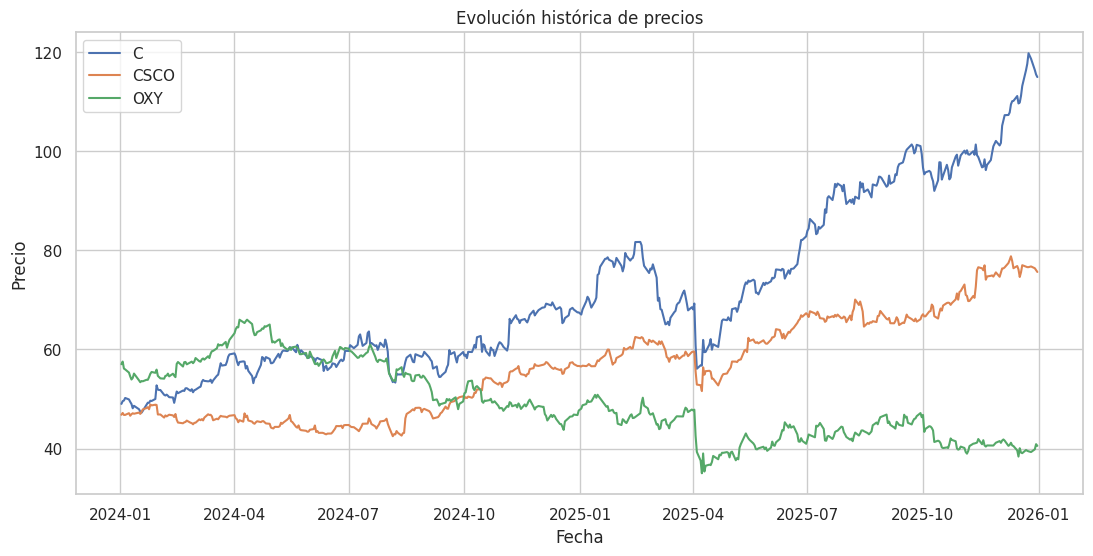

In [8]:
# 2. Graficar precios originales
fig, ax = plt.subplots(figsize=(13, 6))

for ticker in tickers:
    ax.plot(cierre.index, cierre[ticker], label=ticker)

ax.set_title("Evolución histórica de precios")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio")
ax.legend()

plt.show()

In [10]:
# 3. Normalizar y graficar en base 100
cierre_normalizado = cierre / cierre.iloc[0] * 100

cierre_normalizado.head()

Ticker,C,CSCO,OXY
Date,,,
2024-01-02,100.000000,100.000000,100.000000
2024-01-03,101.131220,100.778116,100.932576
2024-01-04,101.376318,99.920188,98.451295
2024-01-05,102.432124,99.940117,98.151540
2024-01-08,101.828800,100.678343,97.035816


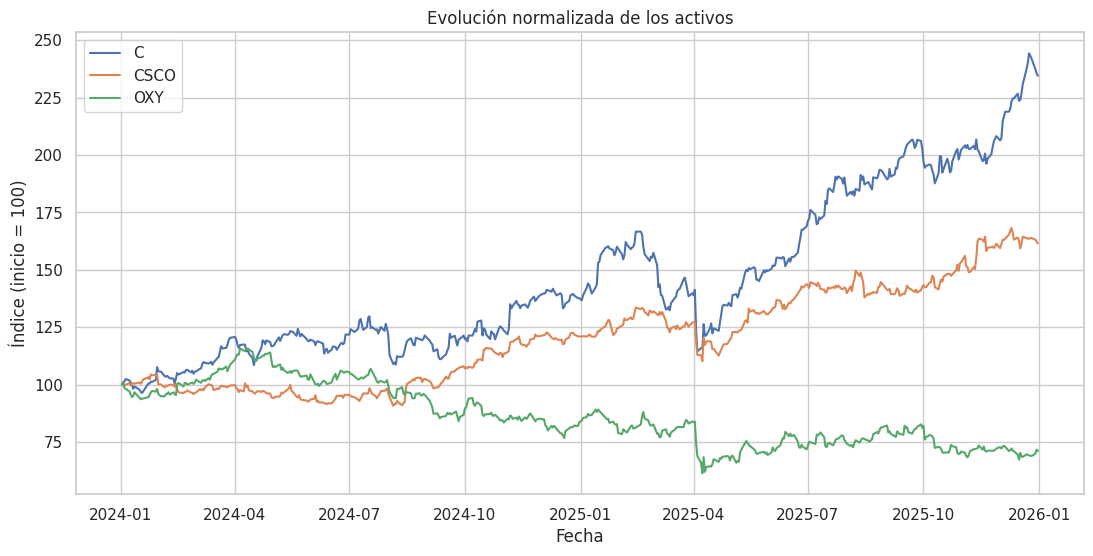

In [13]:
fig, ax = plt.subplots(figsize=(13, 6))

for ticker in tickers:
    ax.plot(
        cierre_normalizado.index,
        cierre_normalizado[ticker],
        label=ticker
    )

ax.set_title("Evolución normalizada de los activos")
ax.set_xlabel("Fecha")
ax.set_ylabel("Índice (inicio = 100)")
ax.legend()

plt.show()

###**INTERPRETACIÓN**
Desde un punto de vista metodológico, el gráfico de precios normalizados es sustancialmente más correcto para comparar el rendimiento histórico por las siguientes razones:

**1.Eliminación del sesgo de escala inicial (Efecto de Base de Precio):** En el gráfico de precios originales, los activos parten de niveles nominales distintos (por ejemplo, OXY comienza cerca de 57 al igual que C, mientras que CSCO ronda los 47). Si un activo con un precio nominal bajo experimenta un gran crecimiento porcentual, visualmente puede parecer menos impresionante que un movimiento absoluto más pequeño de un activo con un precio nominal más alto. Al normalizar a una base común (Base 100) en la fecha de inicio, eliminamos esta distorsión física y visual.

**2.Comparación directa del Rendimiento Acumulado:** El gráfico normalizado muestra directamente la evolución del crecimiento de la inversión inicial. Si al final del periodo un activo llega a 234 (como el caso de C), significa que ha crecido un 134% desde su origen. En cambio, si termina en 71 (como OXY), se entiende que ha perdido un 29% de su valor. En el gráfico original, resulta sumamente complejo calcular e identificar estas magnitudes de rendimiento acumulado a simple vista.

**3.Diferencia en el comportamiento visual observado:**



*   En el gráfico original: Los movimientos de los tres activos parecen estar en un rango visual estrecho durante la primera mitad del periodo de tiempo. El desplome o la subida de los activos no muestra una dimensión clara de su magnitud real en relación a lo invertido.

*  En el gráfico normalizado: Se aprecia de inmediato la divergencia en el desempeño de los activos. Se observa con absoluta claridad que C (Citigroup) fue el activo con el mejor desempeño, superando con creces la duplicación de su valor inicial, seguido por un sólido crecimiento de CSCO y un rendimiento netamente negativo (destrucción de valor) por parte de OXY.




## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

In [12]:
# 1. Calcular rendimientos
rendimientos = cierre.pct_change()

rendimientos.head()

rendimientos = rendimientos.dropna()

rendimientos.head()




Ticker,C,CSCO,OXY
Date,,,
2024-01-03,0.011312,0.007781,0.009326
2024-01-04,0.002424,-0.008513,-0.024584
2024-01-05,0.010415,0.000199,-0.003045
2024-01-08,-0.005890,0.007387,-0.011367
2024-01-09,-0.009813,-0.010900,-0.013901


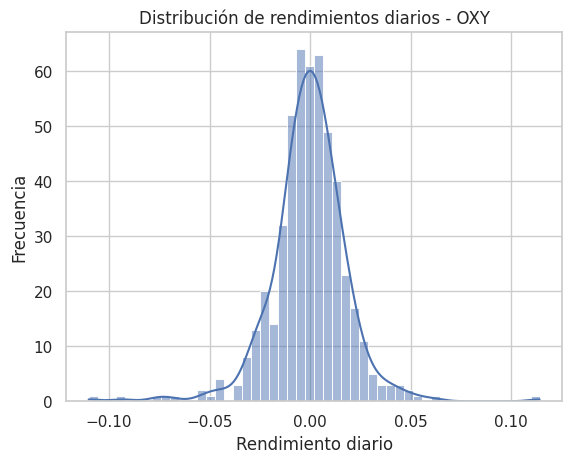

In [18]:
# 2. Histograma con el activo más volátil
sns.histplot(
    data=rendimientos,
    x="OXY",
    bins=50,
    kde=True
)

plt.title("Distribución de rendimientos diarios - OXY")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")

plt.show()

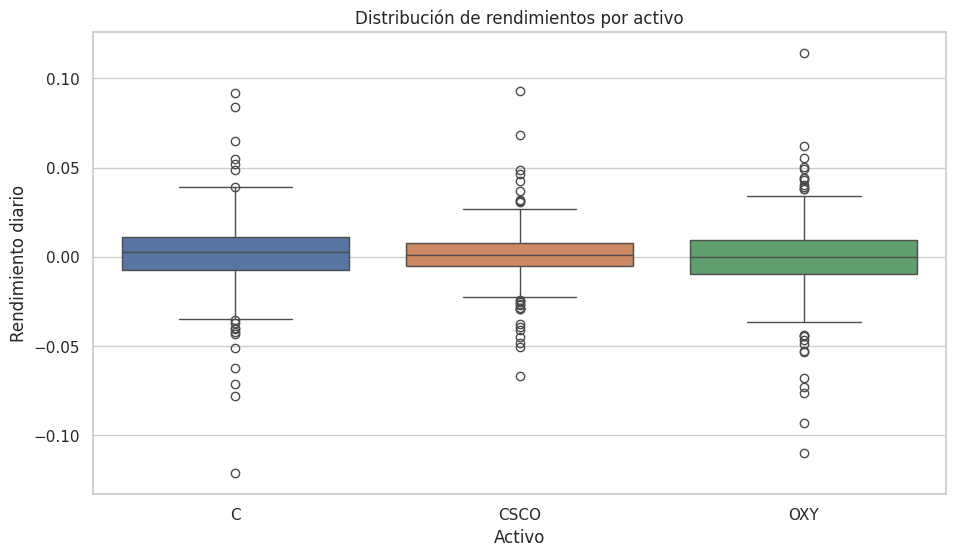

In [15]:
# 3. Boxplot comparativo de rendimientos
plt.figure(figsize=(11, 6))

sns.boxplot(data=rendimientos)

plt.title("Distribución de rendimientos por activo")
plt.xlabel("Activo")
plt.ylabel("Rendimiento diario")

plt.show()

###**INTERPRETACIÓN**
**1. Mayor Dispersión y Riesgo**

*   Activo con mayor dispersión: OXY presenta  la caja ligeramente más amplia y, sobre todo, los bigotes y la distribución de puntos más extendida, seguida muy de cerca por C.

*  ¿Qué nos dice esto sobre su riesgo? OXY presente mayor dispersión significa que sus rendimientos diarios experimentan variaciones extremas con más frecuencia. Un inversor en OXY asume un mayor riesgo de sufrir pérdidas severas en un solo día, pero también la posibilidad de obtener ganancias rápidas en comparación con un activo de caja más compacta como CSCO, que se comporta de manera mucho más estable y predecible.

**2. Identificación de Valores Atípicos (Outliers)**
* Presencia de Outliers: Sí, se identifican numerosos valores atípicos representados como puntos individuales fuera de los bigotes del Boxplot en los tres activos.En C, destaca un rendimiento negativo extremo que supera el -12%. En OXY, destaca un rendimiento positivo atípico muy pronunciado que supera el +11%, además de múltiples caídas extremas cercanas al -10%.En CSCO, los outliers están más agrupados pero igualmente presentes en ambos extremos.
* ¿Qué representan estos puntos en el contexto de la historia económica reciente? Los valores atípicos en finanzas no son errores de medición; representan reacciones extremas del mercado ante eventos macroeconómicos o corporativos de alto impacto durante el periodo 2024-2026.









## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

In [16]:
# 1. Calcular matriz de correlación

correlacion = rendimientos.corr()

correlacion

Ticker,C,CSCO,OXY
Ticker,,,
C,1.000000,0.507815,0.353528
CSCO,0.507815,1.000000,0.299502
OXY,0.353528,0.299502,1.000000


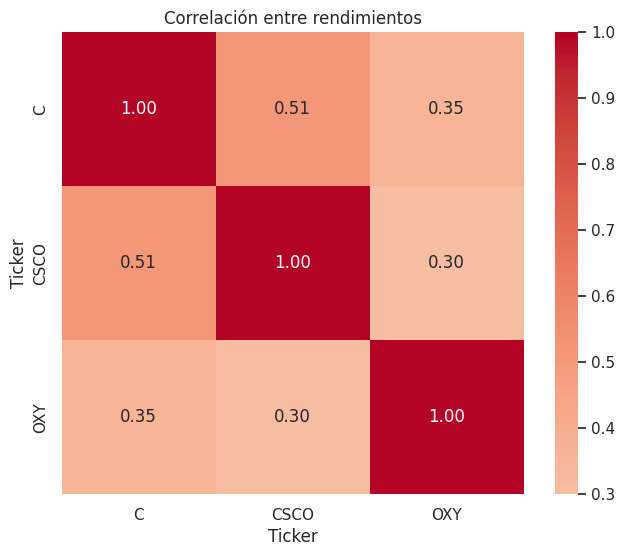

In [17]:
# 2. Dibujar el Heatmap utilizando Seaborn
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlación entre rendimientos")

plt.show()

###**INTEPRETACIÓN**
**1. ¿Existe alguna correlación fuerte (cercana a 1 o -1)?**
No. Ninguno de los pares de activos presenta una correlación fuerte. La relación más estrecha se da entre C y CSCO con un valor de 0.51.

**2. Elección de activos para maximizar la diversificación**
Si tuviera que armar un portafolio buscando minimizar el riesgo conjunto, el par de activos ideal a elegir sería CSCO y OXY porque es la correlación más baja de todo el análisis y al tener una relación tan baja, los días en que un activo sufra caídas debido a factores específicos de su industria, es muy probable que el otro no se vea afectado de la misma forma, amortiguando las pérdidas del portafolio global.



## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [19]:
# Generar resumen de estadísticas descriptivas (Media, Mediana,
# Desviación estándar, Mínimo y Máximo)

resumen = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desviación estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max()
})

resumen


,Media,Mediana,Desviación estándar,Mínimo,Máximo
Ticker,,,,,
C,0.001869,0.002579,0.018206,-0.121377,0.091543
CSCO,0.001045,0.000841,0.013271,-0.066764,0.092875
OXY,-0.000500,-0.000176,0.018912,-0.110075,0.114096


### **CONCLUSIÓN Y RECOMENDACIÓN PARA EL INVERSIONISTA**

**Estimado Inversionista,**

Tras realizar un análisis exhaustivo del comportamiento histórico de los activos **C**, **CSCO** y **OXY** durante el período de 2024 a 2026, le presento las siguientes conclusiones clave basadas en las estadísticas descriptivas para guiar sus futuras decisiones de asignación de capital:

1. **C**
   * **Rendimiento Promedio:** Presenta el mayor rendimiento medio diario de los tres activos (**0.187%**), acompañado de una mediana positiva sólida (**0.258%**). Esto confirma que no solo tuvo días excepcionales, sino que su tendencia general diaria fue consistentemente alcista.
   * **Riesgo:** Su desviación estándar (**1.82%**) es menor que la de OXY, ofreciendo un excelente balance retorno-riesgo (eficiencia de Sharpe histórica superior en este periodo).

2. **CSCO**
   * **Riesgo:** Es, con diferencia, el activo más estable del portafolio, registrando la menor desviación estándar (**1.33%**) y las pérdidas máximas diarias más acotadas (**-6.68%**).
   * **Rendimiento:** Aunque su rendimiento promedio diario (**0.104%**) es menor que el de C, su estabilidad lo convierte en el ancla perfecta para mitigar la volatilidad global de su portafolio.

3. **OXY**
   * **Rendimiento:** Registró una media diaria negativa (**-0.050%**), lo que se tradujo en una pérdida de valor acumulado al final del periodo (terminando alrededor del 71% de su valor inicial).
   * **Riesgo:** Es el activo más volátil del grupo con una desviación estándar del **1.89%** y movimientos extremos de rango muy amplio (un mínimo de **-11.01%** y un máximo de **11.41%**).

### **Recomendación Estratégica:**
Para un perfil de inversión **moderado**, le sugerimos estructurar un portafolio combinando **C** y **CSCO**. Esta combinación le permite capturar el fuerte impulso de crecimiento de Citigroup respaldado por el colchón de baja volatilidad de Cisco. Debido a la baja correlación de **OXY** con los otros dos activos, únicamente recomendaríamos incorporar una pequeña participación marginal de este activo si su objetivo principal es la cobertura sistemática contra choques en los precios de las materias primas energéticas, aceptando el costo de su actual rendimiento esperado negativo.

###**C